Loading the processed data

In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv("../data/processed/climate_processed.csv")

df["Date"] = pd.to_datetime(df["Date"])

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (7310, 24)


,Date,City,State,Temperature_Max,Temperature_Min,Temperature_Avg,Humidity,Rainfall,Wind_Speed (km/h),AQI,...,Month,Day,Temperature_Stress,Rainfall_Level,AQI_Severity,Heat_Risk,Air_Risk,Water_Risk,Climate_Risk_Score,Climate_Risk
0,2024-01-01,Mumbai,Maharashtra,32.5,18.0,25.2,77.6,0.0,3.3,259,...,1,1,7.3,No Rain,3.0,2,4,4,3.30,High
1,2024-01-01,Delhi,Delhi,25.4,10.7,18.1,84.1,0.0,9.0,130,...,1,1,7.3,No Rain,2.0,1,3,4,2.55,Moderate
2,2024-01-01,Bengaluru,Karnataka,37.2,30.8,34.0,49.0,3.7,6.6,54,...,1,1,3.2,Low,1.0,3,2,3,2.60,Moderate
3,2024-01-01,Chennai,Tamil Nadu,37.2,30.4,33.8,34.2,9.5,9.0,176,...,1,1,3.4,Low,2.0,3,3,2,2.75,Moderate
4,2024-01-01,Kolkata,West Bengal,27.4,17.5,22.5,32.2,9.1,9.2,97,...,1,1,4.9,Low,1.0,1,2,2,1.65,Low


Sorting the data correctly


In [2]:
df = df.sort_values(["City", "Date"]).reset_index(drop=True)

print(df[["City", "Date"]].head(10))

        City       Date
0  Ahmedabad 2024-01-01
1  Ahmedabad 2024-01-02
2  Ahmedabad 2024-01-03
3  Ahmedabad 2024-01-04
4  Ahmedabad 2024-01-05
5  Ahmedabad 2024-01-06
6  Ahmedabad 2024-01-07
7  Ahmedabad 2024-01-08
8  Ahmedabad 2024-01-09
9  Ahmedabad 2024-01-10


In [3]:
df["Temp_Avg_Lag1"] = df.groupby("City")["Temperature_Avg"].shift(1)

df["AQI_Lag1"] = df.groupby("City")["AQI"].shift(1)

df["Rainfall_Lag1"] = df.groupby("City")["Rainfall"].shift(1)

df["Humidity_Lag1"] = df.groupby("City")["Humidity"].shift(1)

In [4]:
df["Temp_3Day_Avg"] = (
    df.groupby("City")["Temperature_Avg"]
    .transform(lambda x: x.shift(1).rolling(3).mean())
)

df["AQI_3Day_Avg"] = (
    df.groupby("City")["AQI"]
    .transform(lambda x: x.shift(1).rolling(3).mean())
)

df["Rainfall_3Day_Total"] = (
    df.groupby("City")["Rainfall"]
    .transform(lambda x: x.shift(1).rolling(3).sum())
)

In [5]:
df["Next_Day_Risk"] = (
    df.groupby("City")["Climate_Risk"]
    .shift(-1)
)

In [6]:
df[[
    "City",
    "Date",
    "Temperature_Avg",
    "AQI",
    "Rainfall",
    "Temp_3Day_Avg",
    "AQI_3Day_Avg",
    "Next_Day_Risk"
]].head(15)

,City,Date,Temperature_Avg,AQI,Rainfall,Temp_3Day_Avg,AQI_3Day_Avg,Next_Day_Risk
0,Ahmedabad,2024-01-01,28.9,345,0.0,NaN,NaN,High
1,Ahmedabad,2024-01-02,26.7,223,5.4,NaN,NaN,Moderate
2,Ahmedabad,2024-01-03,29.8,131,5.2,NaN,NaN,Moderate
3,Ahmedabad,2024-01-04,27.0,61,0.0,28.466667,233.000000,High
4,Ahmedabad,2024-01-05,21.6,338,0.0,27.833333,138.333333,High
5,Ahmedabad,2024-01-06,35.5,147,0.0,26.133333,176.666667,Moderate
6,Ahmedabad,2024-01-07,24.7,128,0.0,28.033333,182.000000,High
7,Ahmedabad,2024-01-08,24.0,294,0.0,27.266667,204.333333,Severe
8,Ahmedabad,2024-01-09,35.7,333,0.0,28.066667,189.666667,Moderate
9,Ahmedabad,2024-01-10,21.1,187,0.0,28.133333,251.666667,High


In [7]:
df = df.dropna(
    subset=[
        "Temp_Avg_Lag1",
        "AQI_Lag1",
        "Rainfall_Lag1",
        "Humidity_Lag1",
        "Temp_3Day_Avg",
        "AQI_3Day_Avg",
        "Rainfall_3Day_Total",
        "Next_Day_Risk"
    ]
).reset_index(drop=True)

In [8]:
print("Final dataset shape:", df.shape)

print("\nNext-day risk distribution:")
print(df["Next_Day_Risk"].value_counts())

Final dataset shape: (7270, 32)

Next-day risk distribution:
Next_Day_Risk
High        4129
Moderate    2121
Severe       797
Low          223
Name: count, dtype: int64


In [9]:
print(df["Climate_Risk_Score"].describe())

count    7270.000000
mean        3.025433
std         0.636910
min         1.000000
25%         2.550000
50%         3.000000
75%         3.500000
max         4.400000
Name: Climate_Risk_Score, dtype: float64


In [10]:
print(
    df.groupby("Next_Day_Risk")["Climate_Risk_Score"]
      .agg(["min", "max", "mean", "count"])
)

               min  max      mean  count
Next_Day_Risk                           
High           1.0  4.4  3.036183   4129
Low            1.0  4.4  2.973991    223
Moderate       1.0  4.4  3.008628   2121
Severe         1.0  4.4  3.028858    797


In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

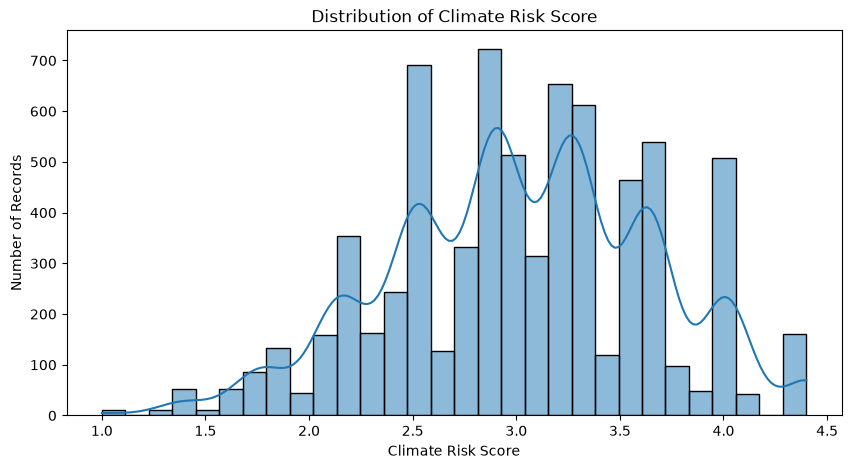

In [13]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df["Climate_Risk_Score"],
    bins=30,
    kde=True
)

plt.title("Distribution of Climate Risk Score")
plt.xlabel("Climate Risk Score")
plt.ylabel("Number of Records")

plt.show()

In [14]:
feature_columns = [
    "Temperature_Max",
    "Temperature_Min",
    "Temperature_Avg",
    "Humidity",
    "Rainfall",
    "Wind_Speed (km/h)",
    "AQI",
    "Pressure_Avg",
    "Cloud_Cover",
    "Temp_Avg_Lag1",
    "AQI_Lag1",
    "Rainfall_Lag1",
    "Humidity_Lag1",
    "Temp_3Day_Avg",
    "AQI_3Day_Avg",
    "Rainfall_3Day_Total",
    "Month"
]

X = df[feature_columns]
y = df["Next_Day_Risk"]

print("Features:", X.shape)
print("Target:", y.shape)

Features: (7270, 17)
Target: (7270,)


In [15]:
X.info()

<class 'pandas.DataFrame'>
RangeIndex: 7270 entries, 0 to 7269
Data columns (total 17 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Temperature_Max      7270 non-null   float64
 1   Temperature_Min      7270 non-null   float64
 2   Temperature_Avg      7270 non-null   float64
 3   Humidity             7270 non-null   float64
 4   Rainfall             7270 non-null   float64
 5   Wind_Speed (km/h)    7270 non-null   float64
 6   AQI                  7270 non-null   int64  
 7   Pressure_Avg         7270 non-null   float64
 8   Cloud_Cover          7270 non-null   float64
 9   Temp_Avg_Lag1        7270 non-null   float64
 10  AQI_Lag1             7270 non-null   float64
 11  Rainfall_Lag1        7270 non-null   float64
 12  Humidity_Lag1        7270 non-null   float64
 13  Temp_3Day_Avg        7270 non-null   float64
 14  AQI_3Day_Avg         7270 non-null   float64
 15  Rainfall_3Day_Total  7270 non-null   float64
 16 

In [16]:
print(X.isnull().sum())

Temperature_Max        0
Temperature_Min        0
Temperature_Avg        0
Humidity               0
Rainfall               0
Wind_Speed (km/h)      0
AQI                    0
Pressure_Avg           0
Cloud_Cover            0
Temp_Avg_Lag1          0
AQI_Lag1               0
Rainfall_Lag1          0
Humidity_Lag1          0
Temp_3Day_Avg          0
AQI_3Day_Avg           0
Rainfall_3Day_Total    0
Month                  0
dtype: int64


In [17]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

y_encoded = label_encoder.fit_transform(y)

print("Classes:", label_encoder.classes_)

Classes: ['High' 'Low' 'Moderate' 'Severe']


In [18]:
print(pd.Series(y_encoded).value_counts())

0    4129
2    2121
3     797
1     223
Name: count, dtype: int64


In [19]:
ml_data = X.copy()
ml_data["Next_Day_Risk"] = y_encoded

ml_data.to_csv(
    "../data/processed/climate_ml_ready.csv",
    index=False
)

print("ML-ready dataset saved successfully.")
print("Shape:", ml_data.shape)

ML-ready dataset saved successfully.
Shape: (7270, 18)


In [20]:
print("Features:", X.shape)
print("Target:", y.shape)
print("Classes:", label_encoder.classes_)
print(pd.Series(y_encoded).value_counts())

Features: (7270, 17)
Target: (7270,)
Classes: ['High' 'Low' 'Moderate' 'Severe']
0    4129
2    2121
3     797
1     223
Name: count, dtype: int64


In [21]:
ml_data = X.copy()

ml_data["Date"] = df["Date"].values
ml_data["Next_Day_Risk"] = y_encoded

ml_data.to_csv(
    "../data/processed/climate_ml_ready.csv",
    index=False
)

print("ML-ready dataset updated successfully.")
print("Shape:", ml_data.shape)
print(ml_data.columns.tolist())

ML-ready dataset updated successfully.
Shape: (7270, 19)
['Temperature_Max', 'Temperature_Min', 'Temperature_Avg', 'Humidity', 'Rainfall', 'Wind_Speed (km/h)', 'AQI', 'Pressure_Avg', 'Cloud_Cover', 'Temp_Avg_Lag1', 'AQI_Lag1', 'Rainfall_Lag1', 'Humidity_Lag1', 'Temp_3Day_Avg', 'AQI_3Day_Avg', 'Rainfall_3Day_Total', 'Month', 'Date', 'Next_Day_Risk']


In [22]:
df["Climate_Risk_Score_Lag1"] = (
    df.groupby("City")["Climate_Risk_Score"].shift(1)
)


In [23]:
risk_encoding = {
    "Low": 0,
    "Moderate": 1,
    "High": 2,
    "Severe": 3
}

df["Climate_Risk_Lag1"] = (
    df.groupby("City")["Climate_Risk"]
    .shift(1)
    .map(risk_encoding)
)

In [24]:
df = df.dropna(
    subset=[
        "Climate_Risk_Score_Lag1",
        "Climate_Risk_Lag1"
    ]
).reset_index(drop=True)


In [25]:
feature_columns = [
    "Temperature_Max",
    "Temperature_Min",
    "Temperature_Avg",
    "Humidity",
    "Rainfall",
    "Wind_Speed (km/h)",
    "AQI",
    "Pressure_Avg",
    "Cloud_Cover",
    "Temp_Avg_Lag1",
    "AQI_Lag1",
    "Rainfall_Lag1",
    "Humidity_Lag1",
    "Temp_3Day_Avg",
    "AQI_3Day_Avg",
    "Rainfall_3Day_Total",
    "Climate_Risk_Score",
    "Climate_Risk_Score_Lag1",
    "Climate_Risk_Lag1",
    "Month"
]

X = df[feature_columns]
y = df["Next_Day_Risk"]

print("Features:", X.shape)
print("Target:", y.shape)

Features: (7260, 20)
Target: (7260,)


In [26]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

y_encoded = label_encoder.fit_transform(y)

print("Classes:", label_encoder.classes_)


Classes: ['High' 'Low' 'Moderate' 'Severe']


In [27]:
ml_data = X.copy()

ml_data["Date"] = df["Date"].values
ml_data["City"] = df["City"].values
ml_data["Next_Day_Risk"] = y_encoded

ml_data.to_csv(
    "../data/processed/climate_ml_ready.csv",
    index=False
)

print("Improved ML-ready dataset saved successfully.")
print("Shape:", ml_data.shape)


Improved ML-ready dataset saved successfully.
Shape: (7260, 23)


In [28]:
original_df = pd.read_csv(
    "../data/processed/climate_processed.csv"
)

original_df["Date"] = pd.to_datetime(original_df["Date"])

original_df = original_df.sort_values(
    ["City", "Date"]
).reset_index(drop=True)

print(original_df.shape)

(7310, 24)


In [29]:
original_df["Next_Day_AQI_Category"] = (
    original_df
    .groupby("City")["AQI_Category"]
    .shift(-1)
)

In [30]:
original_df["AQI_Lag1"] = (
    original_df.groupby("City")["AQI"].shift(1)
)

original_df["AQI_Lag2"] = (
    original_df.groupby("City")["AQI"].shift(2)
)

original_df["AQI_3Day_Avg"] = (
    original_df.groupby("City")["AQI"]
    .transform(lambda x: x.shift(1).rolling(3).mean())
)

In [31]:
original_df["Temperature_Lag1"] = (
    original_df.groupby("City")["Temperature_Avg"].shift(1)
)

original_df["Humidity_Lag1"] = (
    original_df.groupby("City")["Humidity"].shift(1)
)

original_df["Rainfall_Lag1"] = (
    original_df.groupby("City")["Rainfall"].shift(1)
)

original_df["Wind_Lag1"] = (
    original_df.groupby("City")["Wind_Speed (km/h)"].shift(1)
)

In [ ]:
required_columns = [
    "Next_Day_AQI_Category",
    "AQI_Lag1",
    "AQI_Lag2",
    "AQI_3Day_Avg",
    "Temperature_Lag1",
    
    "Humidity_Lag1",
    "Rainfall_Lag1",
    "Wind_Lag1"
]

original_df = original_df.dropna(
    subset=required_columns
).reset_index(drop=True)

print("Final dataset shape:", original_df.shape)

Final dataset shape: (7270, 32)


In [33]:
print(
    original_df["Next_Day_AQI_Category"]
    .value_counts()
)

Next_Day_AQI_Category
Moderate        2373
Poor            2332
Satisfactory    1182
Very Poor       1132
Good             251
Name: count, dtype: int64


In [34]:
feature_columns = [
    "Temperature_Max",
    "Temperature_Min",
    "Temperature_Avg",
    "Humidity",
    "Rainfall",
    "Wind_Speed (km/h)",
    "Pressure_Avg",
    "Cloud_Cover",
    "AQI_Lag1",
    "AQI_Lag2",
    "AQI_3Day_Avg",
    "Temperature_Lag1",
    "Humidity_Lag1",
    "Rainfall_Lag1",
    "Wind_Lag1",
    "Month"
]

X = original_df[feature_columns]

y = original_df["Next_Day_AQI_Category"]

print("Features:", X.shape)
print("Target:", y.shape)

Features: (7270, 16)
Target: (7270,)


In [35]:
from sklearn.preprocessing import LabelEncoder

aqi_encoder = LabelEncoder()

y_encoded = aqi_encoder.fit_transform(y)

print("AQI Classes:")
print(aqi_encoder.classes_)

print("\nEncoded distribution:")
print(pd.Series(y_encoded).value_counts())

AQI Classes:
['Good' 'Moderate' 'Poor' 'Satisfactory' 'Very Poor']

Encoded distribution:
1    2373
2    2332
3    1182
4    1132
0     251
Name: count, dtype: int64


In [36]:
aqi_ml_data = X.copy()

aqi_ml_data["Date"] = original_df["Date"].values
aqi_ml_data["City"] = original_df["City"].values
aqi_ml_data["Next_Day_AQI_Category"] = y_encoded

print("ML-ready dataset shape:", aqi_ml_data.shape)

ML-ready dataset shape: (7270, 19)


In [37]:
aqi_ml_data.to_csv(
    "../data/processed/aqi_prediction_ready.csv",
    index=False
)

print("AQI prediction dataset saved successfully.")

AQI prediction dataset saved successfully.
